# Can an MMM Find the Truth? Calibrating a Media Mix Model with Lift Experiments

**The question.** Marketers set budgets from media-mix-model (MMM) ROI estimates, but those models
can be badly wrong when spend tracks demand: companies spend more *because* sales are about to be high
(peak season), so a model can credit channels for sales that would have happened anyway. Does feeding
the model a small randomized experiment fix its ROI estimates, and does that actually make budget
decisions better?

**How this notebook answers it.** Everything is simulated, so the true ROI of every channel is *known*:

1. Build a 3-year weekly world with five channels, true adstock/saturation/ROI, and built-in confounding.
2. **Model A** - naive regression of sales on spend.
3. **Model B** - Bayesian MMM (PyMC-Marketing: adstock + saturation + seasonality + trend).
4. Simulate a **geo-lift test** (Social off in half the regions for 4 weeks).
5. **Model C** - the same MMM, calibrated with that test.
6. Optimize a fixed **$1M quarterly budget** with each model and score every allocation against the
   *true* response curves.
7. Stress-test the conclusion (stronger priors, an oracle control, a follow-up test, multiple seeds).
8. A one-page recommendation for a marketing VP.

Every number below is computed by this notebook. Nothing in the text is hand-entered.

> **Runtime.** The first run fits ~25 Bayesian models (~1 hour). Fits are cached in `cache/`, so re-running
> is fast. Set `FORCE_REFIT = True` to redo them.


In [1]:
import os
# One BLAS thread per process: PyMC runs several chains in parallel and oversubscribed threads thrash small machines.
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"

import gc, warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression
from IPython.display import Markdown, display

from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from pymc_marketing.prior import Prior

MAIN_SEED = 42                       # the worked example
ROBUSTNESS_SEEDS = [1, 2, 3, 4, 5, 6]  # fresh worlds, not used while developing the pipeline
FORCE_REFIT = False
SAMPLER = dict(chains=4, cores=2, draws=800, tune=800, target_accept=0.95)

CACHE, FIG = Path("cache"), Path("figures")
CACHE.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
COL = {"true": "#111111", "naive": "#8c8c8c", "B": "#3b6ea8", "C": "#e07b24", "D": "#2a9d6f", "oracle": "#7a3b8f"}


## 1. The simulated world (ground truth)

156 weeks of data plus 4 extra weeks reserved for the geo-lift test. Five channels, each with its own
**true** adstock decay, saturation curve and average ROI. The key design choices:

* **Baseline sales** = trend x (1 + yearly seasonality + holiday spikes + an *unobserved demand shock*).
* **Spend is confounded with demand.** Planners anticipate peak season (spend leads it by 3 weeks), chase
  last week's demand, and Social/Display share a campaign-flighting factor, so those two are highly correlated.
* True ROI is fixed *by construction*: each channel's coefficient is solved so its average incremental
  revenue per dollar over the 3 years equals the target below.
* The model-side functional forms differ from the truth (truth: Hill saturation, infinite geometric adstock,
  trend x season is multiplicative; model: logistic saturation, truncated adstock, additive terms), so
  misspecification is part of the test, as in real life.


In [2]:
"""Simulated marketing world with built-in confounding (ground truth known)."""
import numpy as np
import pandas as pd

CHANNELS = ["TV", "Search", "Social", "Display", "Email"]

# True parameters. `roi` is the TRUE average incremental revenue per $ over the
# 3 training years; beta is solved so that it holds exactly.
TRUE = {
    "TV":      dict(alpha=0.60, k_mult=1.2, shape=1.5, roi=1.6, base=28_000, gamma=1.2, theta=1.5, flight=0.0),
    "Search":  dict(alpha=0.10, k_mult=0.8, shape=1.0, roi=3.2, base=14_000, gamma=0.5, theta=3.0, flight=0.0),
    "Social":  dict(alpha=0.30, k_mult=1.5, shape=1.0, roi=2.0, base=14_000, gamma=0.7, theta=2.0, flight=1.0),
    "Display": dict(alpha=0.40, k_mult=1.3, shape=1.0, roi=0.8, base=12_000, gamma=1.0, theta=1.5, flight=1.0),
    "Email":   dict(alpha=0.10, k_mult=0.6, shape=1.0, roi=6.0, base=5_000, gamma=0.1, theta=0.3, flight=0.0),
}
N_TRAIN = 156
N_EXTRA = 4          # weeks after training used for the geo-lift test window
BUFFER = 8           # extra weeks generated so lead/lag shifts don't wrap


def _hol_indicator(dates, month, day, window_days=3):
    out = np.zeros(len(dates))
    for i, d in enumerate(dates):
        target = pd.Timestamp(year=d.year, month=month, day=day)
        if 0 <= (target - d).days < 7:
            out[i] = 1.0
    return out


def _black_friday_week(dates):
    out = np.zeros(len(dates))
    for i, d in enumerate(dates):
        nov1 = pd.Timestamp(year=d.year, month=11, day=1)
        first_thu = nov1 + pd.Timedelta(days=(3 - nov1.weekday()) % 7)
        bf = first_thu + pd.Timedelta(days=21 + 1)  # 4th Thursday + 1
        if 0 <= (bf - d).days < 7:
            out[i] = 1.0
    return out


def adstock(x, alpha):
    """Normalised geometric adstock: steady-state output equals constant input."""
    out = np.zeros_like(x, dtype=float)
    prev = 0.0
    for t, v in enumerate(x):
        prev = (1 - alpha) * v + alpha * prev
        out[t] = prev
    return out


def hill(a, k, s):
    return a**s / (a**s + k**s)


def simulate(seed=42):
    rng = np.random.default_rng(seed)
    T = N_TRAIN + N_EXTRA + BUFFER
    dates = pd.date_range("2021-01-04", periods=T, freq="W-MON")
    doy = dates.dayofyear.to_numpy()
    phi = 2 * np.pi * doy / 365.25

    # --- seasonality + holidays (baseline demand) ---
    season = (0.60 * np.cos(2 * np.pi * (doy - 340) / 365.25)
              + 0.15 * np.sin(2 * phi * 2)
              + 0.08 * np.cos(3 * phi))
    bf = _black_friday_week(dates)
    xmas = _hol_indicator(dates, 12, 25)
    summer = _hol_indicator(dates, 7, 11)
    hol_effect = 0.30 * bf + 0.20 * xmas + 0.12 * summer

    # --- unobserved demand shock (AR1): hits sales AND is reacted to by marketers ---
    u = np.zeros(T)
    for t in range(1, T):
        u[t] = 0.7 * u[t - 1] + rng.normal(0, 0.057)   # stationary sd ~ 0.08

    trend = 1.0 + 0.001 * np.arange(T)
    baseline = 500_000 * trend * (1 + 0.25 * season + hol_effect + u)

    # --- spend: marketers anticipate peak season (lead 3 weeks) and chase demand ---
    plan = np.roll(season, -3) + 0.6 * np.maximum(hol_effect, np.roll(hol_effect, -1)) / 0.3
    plan = plan - plan.mean()
    flight = np.zeros(T)
    for t in range(1, T):
        flight[t] = 0.8 * flight[t - 1] + rng.normal(0, 0.12)   # shared Social/Display campaign flighting
    u_lag = np.roll(u, 1)

    spend = {}
    for c, p in TRUE.items():
        z = (p["gamma"] * plan + p["theta"] * u_lag + p["flight"] * flight
             + rng.normal(0, 0.12, T))
        s = np.exp(z)
        spend[c] = p["base"] * s / s[:N_TRAIN].mean()
    spend = pd.DataFrame(spend, index=dates)

    # --- true response ---
    contrib, beta, kappa = {}, {}, {}
    sales = baseline.copy()
    for c, p in TRUE.items():
        a = adstock(spend[c].to_numpy(), p["alpha"])
        k = p["k_mult"] * a[:N_TRAIN].mean()
        h = hill(a, k, p["shape"])
        b = p["roi"] * spend[c].to_numpy()[:N_TRAIN].sum() / h[:N_TRAIN].sum()
        contrib[c] = b * h
        beta[c], kappa[c] = b, k
        sales = sales + contrib[c]
    noise = rng.normal(0, 12_000, T)
    sales = sales + noise

    df = pd.DataFrame({"date": dates, "sales": sales, "baseline": baseline, "u": u,
                       "black_friday": bf, "christmas": xmas, "summer_sale": summer})
    for c in CHANNELS:
        df[c] = spend[c].to_numpy()
        df[f"contrib_{c}"] = contrib[c]
    world = dict(df=df, beta=beta, kappa=kappa, rng_seed=seed)
    # drop the leading buffer? (buffer is at the END; keep first N_TRAIN+N_EXTRA weeks)
    world["df"] = df.iloc[: N_TRAIN + N_EXTRA].reset_index(drop=True)
    return world


def true_roi(world):
    d = world["df"].iloc[:N_TRAIN]
    return {c: d[f"contrib_{c}"].sum() / d[c].sum() for c in CHANNELS}


def true_weekly_response(world, channel, spend_level):
    """Steady-state weekly incremental sales from constant weekly spend."""
    p = TRUE[channel]
    return world["beta"][channel] * hill(spend_level, world["kappa"][channel], p["shape"])


def true_quarter_sales(world, alloc_weekly):
    """True incremental sales over a 13-week quarter for a constant weekly allocation."""
    return 13 * sum(true_weekly_response(world, c, alloc_weekly[c]) for c in CHANNELS)


# ---------------------------------------------------------------------------
# Geo-lift experiment: one channel switched OFF in half the regions for 4 weeks
# ---------------------------------------------------------------------------
# Each channel's test is run in different weeks/regions in practice, so its measurement error is independent of the others.
# (Social's offset is 0 so the Social off-test is unchanged.)
CHANNEL_SEED_OFFSET = {"TV": 101, "Search": 202, "Social": 0, "Display": 303, "Email": 404}

REGION_SHARES = np.array([0.22, 0.16, 0.13, 0.11, 0.09, 0.08, 0.07, 0.06, 0.05, 0.03])
REGION_NOISE_SD = 0.04      # weekly multiplicative noise per region
PRE_WEEKS = 8


def run_geo_test(world, channel="Social", seed=7, change=-1.0):
    """Simulate a geo-lift test on `channel` in the 4 weeks after the training data.

    `change` is the relative spend change in treated regions (-1.0 = switch off, +0.5 = raise 50%).

    Regions are paired by size and randomised within pairs; treated regions get zero
    spend for the 4-week window. The analyst estimates the weekly sales lost with a
    difference-in-differences across regions (pre-period = last 8 training weeks).
    """
    rng = np.random.default_rng(seed)
    df = world["df"]
    t0 = N_TRAIN
    weeks = np.arange(t0 - PRE_WEEKS, t0 + N_EXTRA)
    p = TRUE[channel]

    spend_on = df[channel].to_numpy().copy()
    spend_off = spend_on.copy()
    spend_off[t0:] = spend_on[t0:] * (1.0 + change)

    def contrib(spend):
        a = adstock(spend, p["alpha"])
        return world["beta"][channel] * hill(a, world["kappa"][channel], p["shape"])

    c_on, c_off = contrib(spend_on), contrib(spend_off)
    expected_other = (df["baseline"].to_numpy()
                      + sum(df[f"contrib_{c}"].to_numpy() for c in CHANNELS if c != channel))

    order = np.argsort(-REGION_SHARES)
    treated = np.zeros(len(REGION_SHARES), dtype=bool)
    for i in range(0, len(order), 2):
        treated[rng.choice(order[i:i + 2])] = True

    rows = []
    for r in range(len(REGION_SHARES)):
        eps = rng.normal(0, REGION_NOISE_SD, len(weeks))
        for j, t in enumerate(weeks):
            ch = c_off[t] if (treated[r] and t >= t0) else c_on[t]
            rows.append(dict(region=r, week=t, treated=bool(treated[r]), post=bool(t >= t0),
                             y=(expected_other[t] + ch) * np.exp(eps[j])))   # share-normalised sales
    panel = pd.DataFrame(rows)

    d = panel.groupby(["region", "treated", "post"]).y.mean().unstack("post")
    d["did"] = d[True] - d[False]
    d = d.reset_index()
    t_d, c_d = d[d.treated].did.to_numpy(), d[~d.treated].did.to_numpy()
    effect = t_d.mean() - c_d.mean()               # weekly sales change caused by the spend change
    se = np.sqrt(t_d.var(ddof=1) / len(t_d) + c_d.var(ddof=1) / len(c_d))
    x = df[channel].iloc[t0:t0 + N_EXTRA].mean()   # weekly spend level before the change

    # PyMC-Marketing requires measured lift and spend change to share a sign. A wrong-sign measurement is pure noise
    # (the true effect is never of the opposite sign), so it is passed as "indistinguishable from zero": a tiny
    # same-sign value with its full standard error, rather than being dropped (dropping would bias the evidence).
    dx = change * x
    wrong_sign = bool(effect * dx <= 0)
    effect_used = np.sign(dx) * 0.01 * se if wrong_sign else effect

    return dict(panel=panel, treated=treated, effect=effect, se=se, x=x, channel=channel, wrong_sign=wrong_sign,
                truth_effect_in_window=float((c_off[t0:] - c_on[t0:]).mean()),
                lift_test=pd.DataFrame({"channel": [channel], "x": [x], "delta_x": [dx],
                                        "delta_y": [effect_used], "sigma": [se]}))


In [3]:
world = simulate(MAIN_SEED)
df = world["df"]; train = df.iloc[:N_TRAIN]
TRUE_ROI = pd.Series(true_roi(world))
mk = sum(train[f"contrib_{c}"] for c in CHANNELS)

print(f"weeks: {N_TRAIN} train + {N_EXTRA} test-window | mean weekly spend ${train[CHANNELS].sum(axis=1).mean():,.0f} "
      f"| marketing share of sales {mk.sum()/train.sales.sum():.1%}")
conf = pd.DataFrame({
    "true ROI": TRUE_ROI,
    "avg weekly spend": train[CHANNELS].mean(),
    "corr(spend, baseline demand)": train[CHANNELS].corrwith(train["baseline"]),
}).round(2)
conf


weeks: 156 train + 4 test-window | mean weekly spend $73,000 | marketing share of sales 22.6%


,true ROI,avg weekly spend,"corr(spend, baseline demand)"
TV,1.6,28000.0,0.81
Search,3.2,14000.0,0.71
Social,2.0,14000.0,0.74
Display,0.8,12000.0,0.77
Email,6.0,5000.0,0.42


Correlation between channel spends (collinearity is what makes MMMs hard):


,TV,Search,Social,Display,Email
TV,1.00,0.73,0.81,0.90,0.45
Search,0.73,1.00,0.74,0.67,0.49
Social,0.81,0.74,1.00,0.89,0.50
Display,0.90,0.67,0.89,1.00,0.42
Email,0.45,0.49,0.50,0.42,1.00


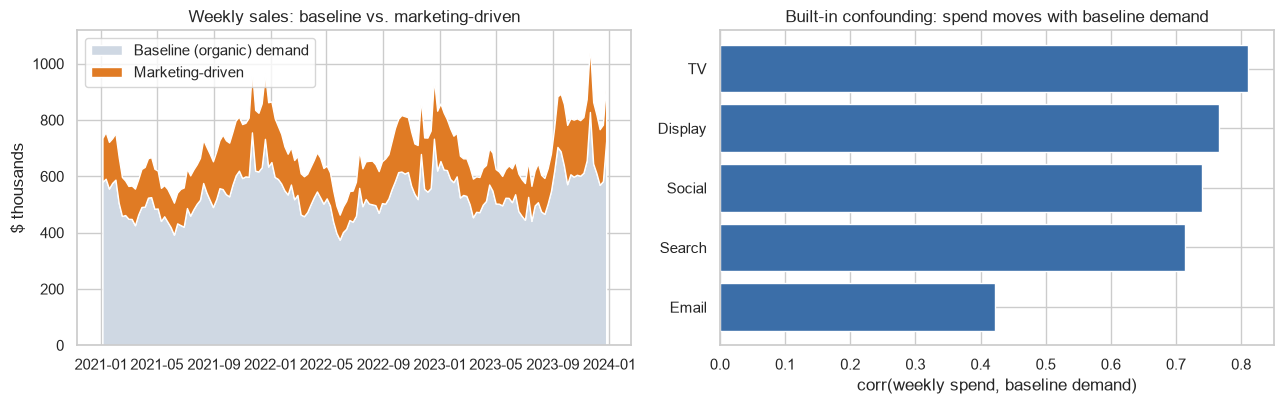

In [4]:
print("Correlation between channel spends (collinearity is what makes MMMs hard):")
display(train[CHANNELS].corr().round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].stackplot(train["date"], train["baseline"] / 1e3, mk / 1e3, labels=["Baseline (organic) demand", "Marketing-driven"],
                colors=["#cfd8e3", "#e07b24"])
ax[0].set_title("Weekly sales: baseline vs. marketing-driven"); ax[0].set_ylabel("$ thousands"); ax[0].legend(loc="upper left")
corr = train[CHANNELS].corrwith(train["baseline"]).sort_values()
ax[1].barh(corr.index, corr.values, color="#3b6ea8")
ax[1].set_title("Built-in confounding: spend moves with baseline demand"); ax[1].set_xlabel("corr(weekly spend, baseline demand)")
plt.tight_layout(); plt.savefig(FIG / "01_world_confounding.png", dpi=150); plt.show()


## 2. Model A: naive regression

Ordinary least squares of weekly sales on weekly spend: the "ROI = coefficient" shortcut. No adstock,
no saturation, no seasonality control. This is the analogue of the *naive estimate is biased* step in a causal analysis.


In [5]:
def naive_roi(train_df):
    lr = LinearRegression().fit(train_df[CHANNELS], train_df["sales"])
    return pd.Series(dict(zip(CHANNELS, lr.coef_)))

NAIVE = naive_roi(train)
a = pd.DataFrame({"true ROI": TRUE_ROI, "naive ROI": NAIVE, "naive / true": NAIVE / TRUE_ROI}).round(2)
display(a)
print(f"Mean absolute % ROI error, naive: {(abs(NAIVE - TRUE_ROI) / TRUE_ROI).mean():.0%}")


,true ROI,naive ROI,naive / true
TV,1.6,2.81,1.76
Search,3.2,4.82,1.51
Social,2.0,3.05,1.53
Display,0.8,1.68,2.10
Email,6.0,4.74,0.79


Mean absolute % ROI error, naive: 62%


## 3. Model B: Bayesian MMM

PyMC-Marketing with geometric adstock (`l_max=8`) and logistic saturation per channel, two Fourier modes of yearly
seasonality, a linear trend and holiday dummies as controls, and **default priors**. The one thing the analyst
cannot see is the unobserved demand shock that planners react to.

ROI here is the same quantity as the truth: total incremental sales attributed to a channel divided by its total spend.


In [6]:
CTRL = ["trend", "black_friday", "christmas", "summer_sale"]
WEEKLY_BUDGET = 1_000_000 / 13
LO_MULT, HI_MULT = 0.5, 2.0     # a channel may be halved or doubled vs. the current mix, no more


def training_frame(world, extra_controls=()):
    d = world["df"].iloc[:N_TRAIN].copy()
    d["trend"] = np.arange(N_TRAIN) / N_TRAIN
    return d, d[["date"] + CHANNELS + CTRL + list(extra_controls)], d["sales"]


def hdi(a, prob=0.94):
    lo, hi = np.percentile(a, [(1 - prob) / 2 * 100, (1 + prob) / 2 * 100])
    return lo, hi


def _logsat(x, lam):
    return (1 - np.exp(-lam * x)) / (1 + np.exp(-lam * x))


def summarize(m, train_df):
    # Everything downstream needs: ROI draws, response-curve parameters, diagnostics. Keep small, drop the model.
    P = m.idata.posterior
    contrib = P["channel_contribution_original_scale"].sum("date").stack(s=("chain", "draw")).transpose("s", "channel").values
    spend_tot = train_df[CHANNELS].sum().to_numpy()
    roi = pd.DataFrame(contrib / spend_tot, columns=CHANNELS)
    lam = P["saturation_lam"].stack(s=("chain", "draw")).transpose("s", "channel").values
    beta = P["saturation_beta"].stack(s=("chain", "draw")).transpose("s", "channel").values
    idx = np.random.default_rng(0).choice(lam.shape[0], size=min(400, lam.shape[0]), replace=False)
    params = dict(lam=lam[idx], beta=beta[idx], scale=np.asarray(m.channel_scale, dtype=float),
                  target=float(np.asarray(m.target_scale)))
    diag = az.summary(m.idata, var_names=["adstock_alpha", "saturation_lam", "saturation_beta"], kind="diagnostics")
    return dict(
        roi=roi, params=params,
        marketing_share=float(contrib.sum(axis=1).mean() / train_df["sales"].sum()),
        max_rhat=float(diag["r_hat"].max()), min_ess=float(diag["ess_bulk"].min()),
        divergences=int(m.idata.sample_stats["diverging"].sum()),
        n_draws=int(P.sizes["chain"] * P.sizes["draw"]),
    )


def get_model(name, seed, world, lift_tests=None, informed_priors=False, extra_controls=()):
    # Fit (or load from cache) one MMM and return its small summary.
    path = CACHE / f"{name}_seed{seed}.nc"
    d, X, y = training_frame(world, extra_controls)
    cfg = None
    if informed_priors:   # spend-share-scaled HalfNormal on saturation_beta (the documented best practice)
        share = d[CHANNELS].sum() / d[CHANNELS].sum().sum()
        cfg = {"saturation_beta": Prior("HalfNormal", sigma=len(CHANNELS) * share.to_numpy(), dims="channel")}

    def build():
        return MMM(date_column="date", channel_columns=CHANNELS, adstock=GeometricAdstock(l_max=8),
                   saturation=LogisticSaturation(), control_columns=CTRL + list(extra_controls),
                   yearly_seasonality=2, model_config=cfg)

    if path.exists() and not FORCE_REFIT:
        m = MMM.load(str(path))
    else:
        m = build()
        if lift_tests is not None:
            m.build_model(X, y)
            m.add_lift_test_measurements(lift_tests)
        m.fit(X, y, random_seed=seed, progressbar=False, **SAMPLER)
        m.save(str(path))
    out = summarize(m, d)
    del m; gc.collect()
    return out


def roi_table(summary):
    r = summary["roi"]
    return pd.DataFrame({"mean": r.mean(), "lo94": r.quantile(0.03), "hi94": r.quantile(0.97)})


B = get_model("B", MAIN_SEED, world)
print(f"Model B | max R-hat {B['max_rhat']:.3f} | min bulk ESS {B['min_ess']:.0f} | divergences {B['divergences']}/{B['n_draws']}")
print(f"Share of all sales attributed to marketing: {B['marketing_share']:.1%}  (truth: {mk.sum()/train.sales.sum():.1%})")
display(pd.DataFrame({"true ROI": TRUE_ROI, "naive": NAIVE, "MMM (B) mean": roi_table(B)["mean"]}).round(2))


Model B | max R-hat 1.010 | min bulk ESS 792 | divergences 32/3200
Share of all sales attributed to marketing: 61.0%  (truth: 22.6%)


,true ROI,naive,MMM (B) mean
TV,1.6,2.81,6.93
Search,3.2,4.82,7.97
Social,2.0,3.05,1.40
Display,0.8,1.68,1.15
Email,6.0,4.74,16.89


## 4. The geo-lift experiment

After the 3 training years, run a **4-week geo-lift test on Social**: regions are paired by size and randomized
within pairs; Social is switched **off** in 5 of 10 regions. The analyst measures the weekly sales lost with a
difference-in-differences against the last 8 pre-test weeks, with a standard error from the region-level
variation (5 treated vs. 5 control regions, so it is honest about how little data a geo test has).

The result is converted into the four numbers PyMC-Marketing needs (`x`, `delta_x`, `delta_y`, `sigma`),
which constrain the model's *saturation curve* for that channel.

One real-world wrinkle is deliberately left in: a 4-week window captures only part of a slow-decaying channel's
effect (adstock carry-over), and the model assumes steady state, so tests of high-carry-over channels (TV) are biased
toward understating the effect.


channel       x  delta_x  delta_y   sigma
 Social 23320.0 -23320.0 -32815.0 12363.0

True (noise-free) weekly sales lost in the test window: -31,822
Measured: -32,815  (SE 12,363; t = -2.7) -> the test pins Social down to roughly +/-74%


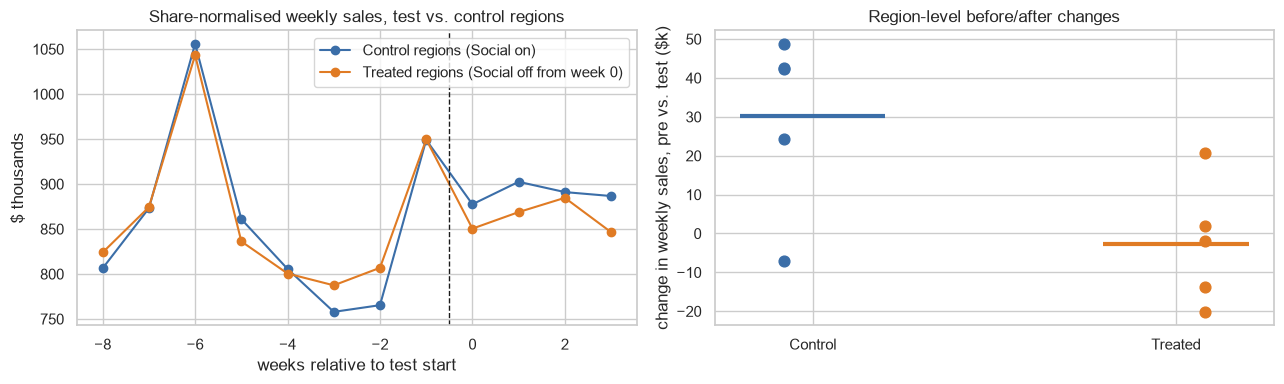

In [7]:
TESTS = {c: run_geo_test(world, c, seed=MAIN_SEED + 1000 + CHANNEL_SEED_OFFSET[c]) for c in CHANNELS}   # only the ones we choose to "run" get used
g = TESTS["Social"]
print(g["lift_test"].round(0).to_string(index=False))
print(f"\nTrue (noise-free) weekly sales lost in the test window: {g['truth_effect_in_window']:,.0f}")
print(f"Measured: {g['effect']:,.0f}  (SE {g['se']:,.0f}; t = {g['effect'] / g['se']:.1f}) -> the test pins Social down to roughly +/-{1.96 * g['se'] / abs(g['effect']):.0%}")

p = g["panel"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for t, lab, c in [(False, "Control regions (Social on)", "#3b6ea8"), (True, "Treated regions (Social off from week 0)", "#e07b24")]:
    s = p[p.treated == t].groupby("week").y.mean() / 1e3
    ax[0].plot(s.index - N_TRAIN, s.values, marker="o", label=lab, color=c)
ax[0].axvline(-0.5, color="k", ls="--", lw=1); ax[0].set_title("Share-normalised weekly sales, test vs. control regions")
ax[0].set_xlabel("weeks relative to test start"); ax[0].set_ylabel("$ thousands"); ax[0].legend()
d = p.groupby(["region", "treated", "post"]).y.mean().unstack("post"); d["did"] = (d[True] - d[False]) / 1e3
dd = d.reset_index()
for t, c, off in [(False, "#3b6ea8", -0.08), (True, "#e07b24", 0.08)]:
    v = dd[dd.treated == t].did.values
    ax[1].scatter(np.full(len(v), float(t)) + off, v, color=c, s=60)
    ax[1].hlines(v.mean(), float(t) - 0.2, float(t) + 0.2, color=c, lw=3)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Control", "Treated"]); ax[1].set_ylabel("change in weekly sales, pre vs. test ($k)")
ax[1].set_title("Region-level before/after changes")
plt.tight_layout(); plt.savefig(FIG / "02_geo_lift_test.png", dpi=150); plt.show()


## 5. Model C: the MMM calibrated with the lift test

Identical to Model B (same data, same default priors, same sampler) except that it is also conditioned on the
Social lift-test measurement.


In [8]:
C = get_model("C", MAIN_SEED, world, lift_tests=TESTS["Social"]["lift_test"])
print(f"Model C | max R-hat {C['max_rhat']:.3f} | min bulk ESS {C['min_ess']:.0f} | divergences {C['divergences']}/{C['n_draws']}")
print(f"Share of all sales attributed to marketing: {C['marketing_share']:.1%}  (truth: {mk.sum()/train.sales.sum():.1%})")


Model C | max R-hat 1.010 | min bulk ESS 920 | divergences 40/3200
Share of all sales attributed to marketing: 60.8%  (truth: 22.6%)


## 6. ROI scoreboard: truth vs. naive vs. MMM vs. calibrated MMM

,true ROI,naive,MMM (B),calibrated (C),B 94% interval,C 94% interval
TV,1.6,2.81,6.93,6.95,2.5 - 11.0,3.0 - 10.9
Search,3.2,4.82,7.97,7.87,5.4 - 12.0,5.5 - 11.6
Social,2.0,3.05,1.40,1.48,0.1 - 4.6,0.4 - 2.6
Display,0.8,1.68,1.15,1.03,0.0 - 4.3,0.0 - 3.9
Email,6.0,4.74,16.89,16.98,0.9 - 66.2,1.0 - 66.8


,TV,Search,Social,Display,Email
abs % error,,,,,
naive,76%,51%,53%,110%,21%
MMM (B),333%,149%,30%,43%,182%
calibrated (C),334%,146%,26%,29%,183%


Average over channels: {'naive': '62%', 'MMM (B)': '147%', 'calibrated (C)': '144%'}
Social (the channel that was tested):    B 30% -> C 26%
Display (correlated with Social):        B 43% -> C 29%
TV / Search / Email (untested, less correlated): B 221% -> C 221%


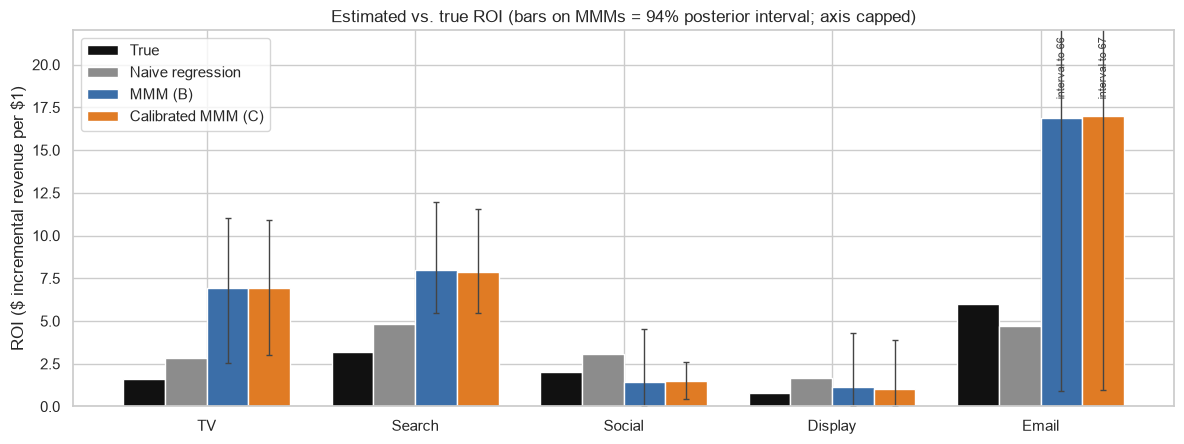

In [9]:
def err(est, truth=TRUE_ROI):
    return (abs(est - truth) / truth)

board = pd.DataFrame({
    "true ROI": TRUE_ROI,
    "naive": NAIVE,
    "MMM (B)": roi_table(B)["mean"],
    "calibrated (C)": roi_table(C)["mean"],
}).round(2)
board["B 94% interval"] = [f"{a:.1f} - {b:.1f}" for a, b in zip(roi_table(B)["lo94"], roi_table(B)["hi94"])]
board["C 94% interval"] = [f"{a:.1f} - {b:.1f}" for a, b in zip(roi_table(C)["lo94"], roi_table(C)["hi94"])]
display(board)

errs = pd.DataFrame({"naive": err(NAIVE), "MMM (B)": err(roi_table(B)["mean"]), "calibrated (C)": err(roi_table(C)["mean"])})
summary_err = errs.mean().to_frame("mean abs % ROI error").T
display((errs * 100).round(0).astype(int).astype(str).add("%").T.rename_axis("abs % error"))
print("Average over channels:", {k: f"{v:.0%}" for k, v in errs.mean().items()})
print(f"Social (the channel that was tested):    B {errs.loc['Social','MMM (B)']:.0%} -> C {errs.loc['Social','calibrated (C)']:.0%}")
print(f"Display (correlated with Social):        B {errs.loc['Display','MMM (B)']:.0%} -> C {errs.loc['Display','calibrated (C)']:.0%}")
others = [c for c in CHANNELS if c not in ("Social", "Display")]
print(f"TV / Search / Email (untested, less correlated): B {errs.loc[others,'MMM (B)'].mean():.0%} -> C {errs.loc[others,'calibrated (C)'].mean():.0%}")

fig, ax = plt.subplots(figsize=(12, 4.6))
w_ = 0.2; x = np.arange(len(CHANNELS))
ax.bar(x - 1.5 * w_, TRUE_ROI[CHANNELS], w_, color=COL["true"], label="True")
ax.bar(x - 0.5 * w_, NAIVE[CHANNELS], w_, color=COL["naive"], label="Naive regression")
for k, (S, off, lab, col) in enumerate([(B, 0.5, "MMM (B)", COL["B"]), (C, 1.5, "Calibrated MMM (C)", COL["C"])]):
    t = roi_table(S).loc[CHANNELS]
    ax.bar(x + off * w_, t["mean"], w_, color=col, label=lab,
           yerr=[t["mean"] - t["lo94"], t["hi94"] - t["mean"]], error_kw=dict(lw=1, capsize=2, ecolor="#444"))
YMAX = 22
ax.set_ylim(0, YMAX)
for j, c in enumerate(CHANNELS):   # intervals that run off the chart are labelled instead of squashing everything else
    for S_, off_ in [(B, 0.5), (C, 1.5)]:
        hi_ = roi_table(S_).loc[c, "hi94"]
        if hi_ > YMAX:
            ax.annotate(f"interval to {hi_:.0f}", (x[j] + off_ * w_, YMAX - 0.4), ha="center", va="top", fontsize=8, rotation=90, color="#444")
ax.set_xticks(x); ax.set_xticklabels(CHANNELS); ax.set_ylabel(r"ROI (\$ incremental revenue per \$1)")
ax.set_title("Estimated vs. true ROI (bars on MMMs = 94% posterior interval; axis capped)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "03_roi_comparison.png", dpi=150); plt.show()


## 7. Response curves

What each model believes about the *shape* of returns (weekly incremental sales as a function of weekly spend)
versus the truth. Budget optimization depends on the **slope** of these curves, not the average ROI.


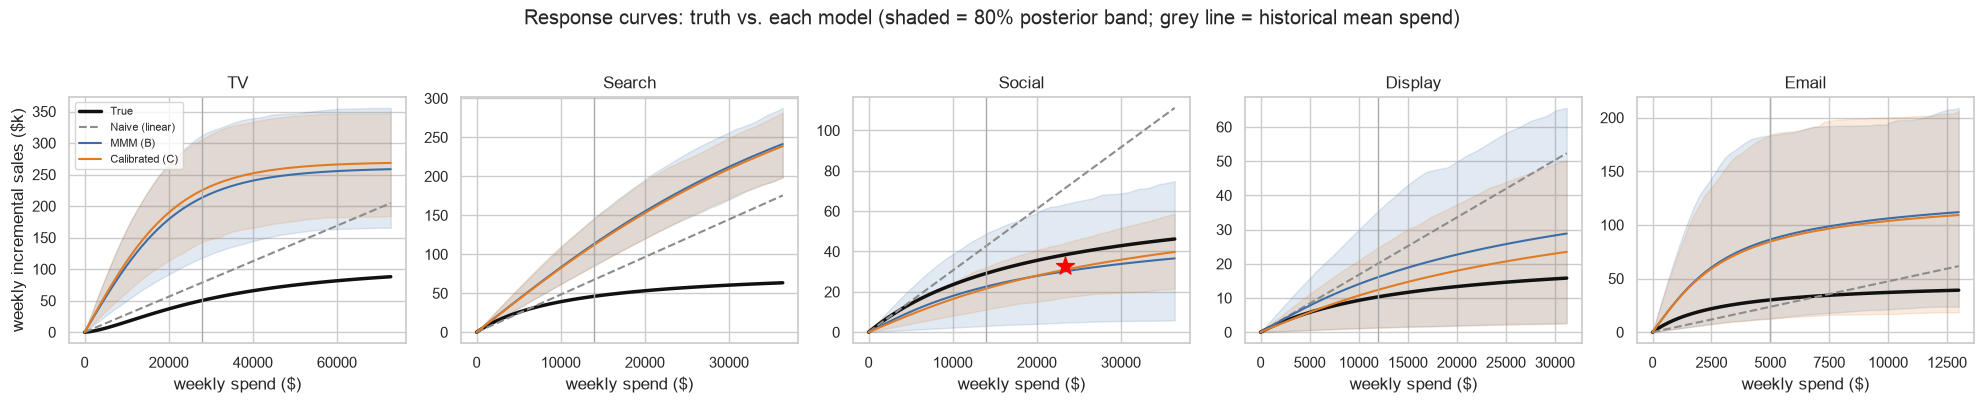

In [10]:
def curve_draws(params, channel, spend):
    j = CHANNELS.index(channel)
    return params["target"] * params["beta"][:, j] * _logsat(spend / params["scale"][j], params["lam"][:, j])

fig, axes = plt.subplots(1, 5, figsize=(20, 3.9))
for ax, c in zip(axes, CHANNELS):
    mean_spend = train[c].mean()
    grid = np.linspace(0, 2.6 * mean_spend, 60)
    ax.plot(grid, [true_weekly_response(world, c, s) / 1e3 for s in grid], color=COL["true"], lw=2.5, label="True")
    ax.plot(grid, NAIVE[c] * grid / 1e3, color=COL["naive"], ls="--", label="Naive (linear)")
    for S, col, lab in [(B, COL["B"], "MMM (B)"), (C, COL["C"], "Calibrated (C)")]:
        cur = np.array([curve_draws(S["params"], c, s) for s in grid]) / 1e3
        ax.plot(grid, cur.mean(1), color=col, label=lab)
        ax.fill_between(grid, *np.percentile(cur, [10, 90], axis=1), color=col, alpha=0.15)
    ax.axvline(mean_spend, color="#aaa", lw=1)
    if c == "Social":
        ax.scatter([g["x"]], [-g["effect"] / 1e3], marker="*", s=180, color="red", zorder=5, label="Lift test (measured)")
    ax.set_title(c); ax.set_xlabel("weekly spend ($)")
axes[0].set_ylabel("weekly incremental sales ($k)"); axes[0].legend(fontsize=8)
plt.suptitle("Response curves: truth vs. each model (shaded = 80% posterior band; grey line = historical mean spend)", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "04_response_curves.png", dpi=150, bbox_inches="tight"); plt.show()


## 8. Budget optimization: the business result

Fixed **$1M per quarter**. Each model recommends an allocation by maximizing its own predicted incremental sales,
subject to a realistic planning rule (no channel more than doubled or halved relative to the current mix).
Then every allocation is scored against the **true** response curves, the only number that matters.

* *Historical mix* = current spend proportions, scaled to $1M.
* *Oracle* = what you would do if you knew the true curves (the ceiling under the same rule).
* The naive model is linear, so it goes to the corners (maximum into its highest-ROI channels).


,TV ($k),Search ($k),Social ($k),Display ($k),Email ($k),true quarterly incremental sales,vs naive (%),vs historical (%),gain captured (%)
historical mix,384.0,192.0,192.0,164.0,68.0,2225726.0,5.5,0.0,0.0
naive,192.0,384.0,205.0,82.0,137.0,2109054.0,0.0,-5.2,-159.9
MMM (B),342.0,384.0,96.0,82.0,97.0,2184099.0,3.6,-1.9,-57.1
calibrated (C),344.0,384.0,96.0,82.0,95.0,2184585.0,3.6,-1.8,-56.4
oracle,438.0,205.0,176.0,82.0,99.0,2298684.0,9.0,3.3,100.0


Calibrated MMM's budget delivered +3.6% more TRUE incremental sales than the naive model's; uncalibrated MMM: +3.6%.
Calibrated vs uncalibrated MMM: +0.02%.   Calibrated vs simply keeping the historical mix: -1.8%.


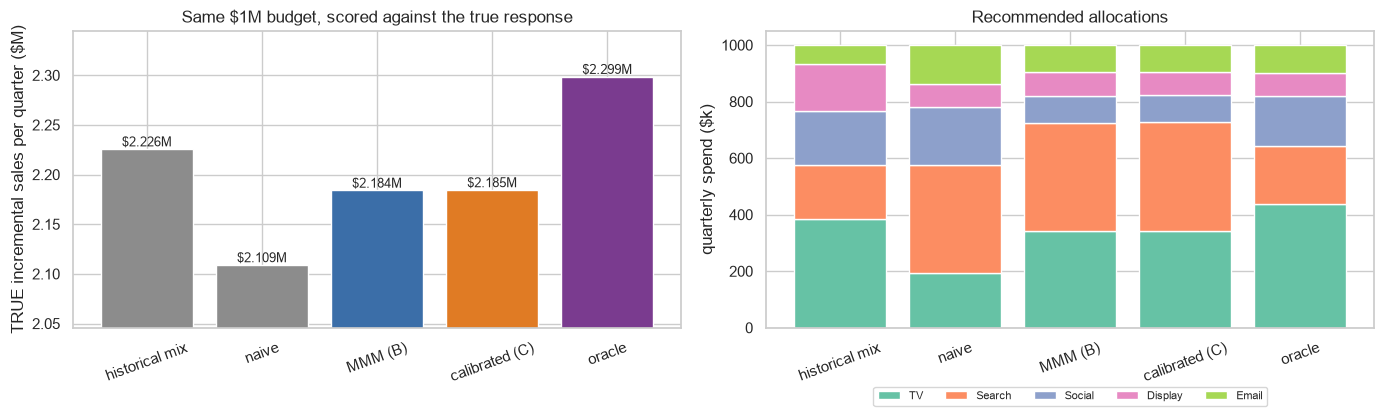

In [11]:
def current_mix_weekly(train_df):
    m = train_df[CHANNELS].mean()
    return (m / m.sum() * WEEKLY_BUDGET).to_dict()


def optimise(response_fn, current):
    x0 = np.array([current[c] for c in CHANNELS])
    res = minimize(lambda x: -sum(response_fn(c, x[i]) for i, c in enumerate(CHANNELS)), x0, method="SLSQP",
                   bounds=[(LO_MULT * v, HI_MULT * v) for v in x0],
                   constraints=[{"type": "eq", "fun": lambda x: x.sum() - WEEKLY_BUDGET}], options={"maxiter": 500, "ftol": 1e-9})
    return dict(zip(CHANNELS, res.x))


bayes_fn = lambda S: (lambda c, x: curve_draws(S["params"], c, x).mean())
linear_fn = lambda roi: (lambda c, x: roi[c] * x)
true_fn = lambda w: (lambda c, x: true_weekly_response(w, c, x))


def budget_table(world, train_df, naive, summaries):
    cur = current_mix_weekly(train_df)
    allocs = {"historical mix": cur, "naive": optimise(linear_fn(naive), cur)}
    for k, S in summaries.items():
        allocs[k] = optimise(bayes_fn(S), cur)
    allocs["oracle"] = optimise(true_fn(world), cur)
    t = pd.DataFrame({k: {**{c: a[c] * 13 for c in CHANNELS}, "true quarterly incremental sales": true_quarter_sales(world, a)}
                      for k, a in allocs.items()}).T
    h, o, n = t.loc["historical mix", "true quarterly incremental sales"], t.loc["oracle", "true quarterly incremental sales"], t.loc["naive", "true quarterly incremental sales"]
    t["vs naive"] = t["true quarterly incremental sales"] / n - 1
    t["vs historical"] = t["true quarterly incremental sales"] / h - 1
    t["share of achievable gain captured"] = (t["true quarterly incremental sales"] - h) / (o - h)
    return t, allocs


bt, allocs = budget_table(world, train, NAIVE, {"MMM (B)": B, "calibrated (C)": C})
show = bt.copy()
for c in CHANNELS: show[c] = (show[c] / 1e3).round(0)
show["true quarterly incremental sales"] = show["true quarterly incremental sales"].round(0)
for c in ["vs naive", "vs historical", "share of achievable gain captured"]: show[c] = (show[c] * 100).round(1)
show = show.rename(columns={**{c: f"{c} ($k)" for c in CHANNELS}, "vs naive": "vs naive (%)", "vs historical": "vs historical (%)",
                            "share of achievable gain captured": "gain captured (%)"})
display(show)

n_, b_, c_ = (bt.loc[k, "true quarterly incremental sales"] for k in ["naive", "MMM (B)", "calibrated (C)"])
print(f"Calibrated MMM's budget delivered {c_/n_-1:+.1%} more TRUE incremental sales than the naive model's; uncalibrated MMM: {b_/n_-1:+.1%}.")
print(f"Calibrated vs uncalibrated MMM: {c_/b_-1:+.2%}.   Calibrated vs simply keeping the historical mix: {bt.loc['calibrated (C)','vs historical']:+.1%}.")

order = ["historical mix", "naive", "MMM (B)", "calibrated (C)", "oracle"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
vals = bt.loc[order, "true quarterly incremental sales"] / 1e6
ax[0].bar(order, vals, color=[COL["naive"], COL["naive"], COL["B"], COL["C"], COL["oracle"]])
ax[0].set_ylim(vals.min() * 0.97, vals.max() * 1.02)
for i, v in enumerate(vals): ax[0].text(i, v, f"${v:.3f}M", ha="center", va="bottom", fontsize=9)
ax[0].set_ylabel("TRUE incremental sales per quarter ($M)"); ax[0].set_title("Same $1M budget, scored against the true response")
ax[0].tick_params(axis="x", rotation=20)
pal = sns.color_palette("Set2", 5)
bottom = np.zeros(len(order))
for j, c in enumerate(CHANNELS):
    v = bt.loc[order, c].to_numpy() / 1e3
    ax[1].bar(order, v, bottom=bottom, color=pal[j], label=c); bottom += v
ax[1].set_ylabel("quarterly spend ($k)"); ax[1].set_title("Recommended allocations"); ax[1].legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG / "05_budget_comparison.png", dpi=150, bbox_inches="tight"); plt.show()


## 9. Stress tests on the main world

A single comparison can mislead, so before reading anything into Models B and C, a set of checks on the main world:

* **B+ / C+**: the same models with spend-share-informed priors on channel effects (the documented best practice), so
  calibration is not just beating a weak baseline.
* **Oracle control (OC)**: give the MMM the *unobserved demand shock* as a control. If confounding by that shock were the
  whole story, ROI error should collapse.
* **Follow the recommendation (D)**: pick the next channel to test by a rule fixed in advance (largest posterior uncertainty
  in attributed incremental sales among untested channels), simulate that test, and recalibrate.
* **Ceiling (E)**: calibrate with a switch-off test on *every* channel, the best case for the experiment we ran.
* **Two-level tests (E2)**: off-tests *plus* a halve-spend test on every channel, so each channel's curve is constrained at
  two points instead of one. (Power check below: a +50% test is mostly noise, so the second level is a *cut*.)


In [12]:
# Statistical power of different test designs (noise-free true effect over the measurement SE), main world
rows = []
for c in CHANNELS:
    r = {"channel": c}
    for ch, lab in [(-1.0, "switch off"), (-0.5, "halve"), (0.5, "+50%")]:
        t = run_geo_test(world, c, seed=MAIN_SEED + 3000 + CHANNEL_SEED_OFFSET[c], change=ch)
        r[f"{lab}"] = abs(t["truth_effect_in_window"]) / t["se"]
    rows.append(r)
display(pd.DataFrame(rows).set_index("channel").round(2).rename_axis("|true effect| / SE").T)


|true effect| / SE,TV,Search,Social,Display,Email
switch off,3.14,2.80,3.84,0.49,2.28
halve,1.26,0.80,1.27,0.16,0.66
+50%,0.81,0.43,0.77,0.10,0.36


In [13]:
def next_test_channel(summary, train_df, exclude=("Social",)):
    # Rule fixed before looking at results: largest 94%-interval width of attributed incremental sales ($), untested channels only.
    spend = train_df[CHANNELS].sum()
    width = {c: (lambda lo, hi: hi - lo)(*hdi(summary["roi"][c].to_numpy() * spend[c])) for c in CHANNELS if c not in exclude}
    return max(width, key=width.get), width


def concat_tests(*chs, tests):
    return pd.concat([tests[c]["lift_test"] for c in chs], ignore_index=True)


def all_tests(seed, w):
    off = {c: run_geo_test(w, c, seed=seed + 1000 + CHANNEL_SEED_OFFSET[c]) for c in CHANNELS}
    half = {c: run_geo_test(w, c, seed=seed + 2000 + CHANNEL_SEED_OFFSET[c], change=-0.5) for c in CHANNELS}
    return off, half


TESTS_HALF = all_tests(MAIN_SEED, world)[1]
NEXT, widths = next_test_channel(C, train)
print("Posterior uncertainty (94% interval width of incremental sales, $M) among untested channels:",
      {k: round(v / 1e6, 1) for k, v in widths.items()}, "-> next test:", NEXT)

Bp = get_model("Bplus", MAIN_SEED, world, informed_priors=True)
Cp = get_model("Cplus", MAIN_SEED, world, lift_tests=TESTS["Social"]["lift_test"], informed_priors=True)
OC = get_model("OC", MAIN_SEED, world, extra_controls=("u",))
D = get_model(f"D_{NEXT}", MAIN_SEED, world, lift_tests=concat_tests("Social", NEXT, tests=TESTS))
E = get_model("E_all", MAIN_SEED, world, lift_tests=concat_tests(*CHANNELS, tests=TESTS))
E2 = get_model("E2_all", MAIN_SEED, world,
               lift_tests=pd.concat([concat_tests(*CHANNELS, tests=TESTS), concat_tests(*CHANNELS, tests=TESTS_HALF)], ignore_index=True))


def coverage(summary, truth):
    t = roi_table(summary)
    return float(((t["lo94"] <= truth) & (truth <= t["hi94"])).mean())


variants = {"naive": None, "B: MMM": B, "C: + Social test": C, "B+: informed priors": Bp, "C+: informed + Social test": Cp,
            "OC: MMM + true confounder": OC, f"D: + Social & {NEXT} tests": D,
            "E: off-tests on all 5": E, "E2: off + halve tests on all 5": E2}
rows = []
for k, S in variants.items():
    est = NAIVE if S is None else roi_table(S)["mean"]
    e = err(est)
    rows.append({"model": k, "mean abs % ROI error": e.mean(), "Social": e["Social"], "Display": e["Display"],
                 "TV": e["TV"], "Search": e["Search"], "Email": e["Email"],
                 "94% intervals containing truth": np.nan if S is None else coverage(S, TRUE_ROI),
                 "marketing share of sales": np.nan if S is None else S["marketing_share"],
                 "R-hat max": np.nan if S is None else S["max_rhat"], "divergences": np.nan if S is None else S["divergences"]})
stress = pd.DataFrame(rows).set_index("model")
fmt = stress.copy()
for c in ["mean abs % ROI error", "Social", "Display", "TV", "Search", "Email", "marketing share of sales", "94% intervals containing truth"]:
    fmt[c] = (fmt[c] * 100).round(0)
print(f"(true marketing share of sales: {mk.sum()/train.sales.sum()*100:.0f}%; values are percentages)")
display(fmt)


Posterior uncertainty (94% interval width of incremental sales, $M) among untested channels: {'TV': np.float64(34.5), 'Search': np.float64(13.3), 'Display': np.float64(7.3), 'Email': np.float64(51.4)} -> next test: Email


(true marketing share of sales: 23%; values are percentages)


,mean abs % ROI error,Social,Display,TV,Search,Email,94% intervals containing truth,marketing share of sales,R-hat max,divergences
model,,,,,,,,,,
naive,62.0,53.0,110.0,76.0,51.0,21.0,NaN,NaN,NaN,NaN
B: MMM,147.0,30.0,43.0,333.0,149.0,182.0,60.0,61.0,1.01,32.0
C: + Social test,144.0,26.0,29.0,334.0,146.0,183.0,60.0,61.0,1.01,40.0
B+: informed priors,161.0,26.0,71.0,331.0,154.0,225.0,60.0,64.0,1.10,228.0
C+: informed + Social test,138.0,27.0,35.0,331.0,151.0,147.0,60.0,59.0,1.00,45.0
OC: MMM + true confounder,121.0,49.0,95.0,393.0,36.0,30.0,80.0,46.0,1.01,60.0
D: + Social & Email tests,116.0,25.0,35.0,333.0,153.0,33.0,60.0,52.0,1.00,1.0
E: off-tests on all 5,33.0,1.0,60.0,36.0,38.0,27.0,60.0,22.0,1.00,0.0
E2: off + halve tests on all 5,26.0,5.0,61.0,34.0,16.0,16.0,80.0,20.0,1.00,0.0


In [14]:
bt2, allocs2 = budget_table(world, train, NAIVE, {k: v for k, v in variants.items() if v is not None})
view = bt2[["true quarterly incremental sales", "vs naive", "vs historical", "share of achievable gain captured"]].copy()
view["true quarterly incremental sales"] = view["true quarterly incremental sales"].round(0)
for c in ["vs naive", "vs historical", "share of achievable gain captured"]: view[c] = (view[c] * 100).round(1)
display(view.rename(columns={"vs naive": "vs naive (%)", "vs historical": "vs historical (%)", "share of achievable gain captured": "gain captured (%)"}))
print(f"Headroom: knowing the true curves would improve on the current mix by only {bt2.loc['oracle','vs historical']:.1%} (under the halve/double rule).")


,true quarterly incremental sales,vs naive (%),vs historical (%),gain captured (%)
historical mix,2225726.0,5.5,0.0,0.0
naive,2109054.0,0.0,-5.2,-159.9
B: MMM,2184099.0,3.6,-1.9,-57.1
C: + Social test,2184585.0,3.6,-1.8,-56.4
B+: informed priors,2184579.0,3.6,-1.8,-56.4
C+: informed + Social test,2185249.0,3.6,-1.8,-55.5
OC: MMM + true confounder,2228490.0,5.7,0.1,3.8
D: + Social & Email tests,2171491.0,3.0,-2.4,-74.3
E: off-tests on all 5,2109054.0,0.0,-5.2,-159.9
E2: off + halve tests on all 5,2109054.0,0.0,-5.2,-159.9


Headroom: knowing the true curves would improve on the current mix by only 3.3% (under the halve/double rule).


### Why a switch-off test can calibrate ROI yet not the budget

A budget optimizer moves money according to **marginal** ROI (the slope of the curve at the current spend), but a
switch-off test measures **average** ROI over the whole spend range. The table compares each model's marginal ROI at current
spend with the truth.


In [15]:
def marginal_roi(S, w_, train_df):
    out = {}
    for c in CHANNELS:
        x0 = train_df[c].mean()
        out[c] = (curve_draws(S["params"], c, x0 + 1000) - curve_draws(S["params"], c, x0)).mean() / 1000
    return out

mt = pd.DataFrame({
    "true average ROI": TRUE_ROI,
    "true marginal ROI": pd.Series({c: (true_weekly_response(world, c, train[c].mean() + 1000) - true_weekly_response(world, c, train[c].mean())) / 1000 for c in CHANNELS}),
    "B marginal": pd.Series(marginal_roi(B, world, train)),
    "C marginal": pd.Series(marginal_roi(C, world, train)),
    "E (off-tests) marginal": pd.Series(marginal_roi(E, world, train)),
    "E2 (off+halve) marginal": pd.Series(marginal_roi(E2, world, train)),
}).round(2)
display(mt)
rank = lambda s: " > ".join(s.sort_values(ascending=False).index)
print("Ranking by marginal ROI (what the optimizer follows):")
for col in ["true marginal ROI", "B marginal", "C marginal", "E (off-tests) marginal", "E2 (off+halve) marginal"]:
    print(f"  {col:26s} {rank(mt[col])}")


,true average ROI,true marginal ROI,B marginal,C marginal,E (off-tests) marginal,E2 (off+halve) marginal
TV,1.6,1.49,3.18,3.23,0.96,1.01
Search,3.2,1.41,7.27,7.15,4.32,2.56
Social,2.0,1.21,1.00,1.18,1.70,1.86
Display,0.8,0.47,0.96,0.80,1.13,1.12
Email,6.0,2.01,5.85,5.76,3.20,3.94


Ranking by marginal ROI (what the optimizer follows):
  true marginal ROI          Email > TV > Search > Social > Display
  B marginal                 Search > Email > TV > Social > Display
  C marginal                 Search > Email > TV > Social > Display
  E (off-tests) marginal     Search > Email > Social > Display > TV
  E2 (off+halve) marginal    Email > Search > Social > Display > TV


## 10. Robustness: fresh worlds

Same pipeline on six *new* simulated worlds. New seeds change the noise, the spend paths, the test randomization and the
tests' measurement error, but **the true channel parameters are the same in every world**, so this checks robustness to
sampling variation, not to different underlying marketing structures (that is why the optimization headroom below is the
same in each). Seed 42 above was used while building the pipeline; these were not. For each world:
Model B, Model C (Social test), Model D (C plus a test on the channel chosen by the rule above), Model E (off-tests on all
channels) and Model E2 (off + halve tests on all channels). Also recorded: how often each model's 94% interval actually
contains the true ROI, and how much room the true curves leave over the current mix.


In [16]:
def evaluate_world(seed, world_=None):
    w = world_ or simulate(seed)
    tr_ = w["df"].iloc[:N_TRAIN]; troi = pd.Series(true_roi(w)); nv = naive_roi(tr_)
    off, half = all_tests(seed, w)
    Bs = get_model("B", seed, w)
    Cs = get_model("C", seed, w, lift_tests=off["Social"]["lift_test"])
    nxt, _ = next_test_channel(Cs, tr_)
    Ds = get_model(f"D_{nxt}", seed, w, lift_tests=concat_tests("Social", nxt, tests=off))
    Es = get_model("E_all", seed, w, lift_tests=concat_tests(*CHANNELS, tests=off))
    E2s = get_model("E2_all", seed, w, lift_tests=pd.concat([concat_tests(*CHANNELS, tests=off), concat_tests(*CHANNELS, tests=half)], ignore_index=True))
    sums = {"MMM (B)": Bs, "calibrated (C)": Cs, "calibrated+next test (D)": Ds,
            "off-tests on all 5 (E)": Es, "off+halve tests on all 5 (E2)": E2s}
    bt_, _ = budget_table(w, tr_, nv, sums)
    rows = []
    for k in ["naive", *sums]:
        est = nv if k == "naive" else roi_table(sums[k])["mean"]
        e = err(est, troi)
        rows.append(dict(seed=seed, model=k, roi_err=e.mean(), social_err=e["Social"], display_err=e["Display"],
                         coverage=np.nan if k == "naive" else coverage(sums[k], troi),
                         true_sales=bt_.loc[k, "true quarterly incremental sales"],
                         vs_naive=bt_.loc[k, "vs naive"], vs_hist=bt_.loc[k, "vs historical"],
                         gain_captured=bt_.loc[k, "share of achievable gain captured"],
                         headroom=bt_.loc["oracle", "vs historical"], next_test=nxt,
                         wrong_sign_tests=sum(t_["wrong_sign"] for t_ in [*off.values(), *half.values()]),
                         test_t=abs(off["Social"]["effect"] / off["Social"]["se"])))
    return pd.DataFrame(rows)


robust = pd.concat([evaluate_world(s, world if s == MAIN_SEED else None) for s in [MAIN_SEED] + ROBUSTNESS_SEEDS], ignore_index=True)
fresh = robust[robust.seed.isin(ROBUSTNESS_SEEDS)]
MODELS = ["naive", "MMM (B)", "calibrated (C)", "calibrated+next test (D)", "off-tests on all 5 (E)", "off+halve tests on all 5 (E2)"]
agg = fresh.groupby("model")[["roi_err", "social_err", "display_err", "coverage", "vs_naive", "vs_hist"]].mean().loc[MODELS]
display((agg * 100).round(1).rename(columns={"roi_err": "ROI error (%)", "social_err": "Social error (%)", "display_err": "Display error (%)",
                                             "coverage": "94% intervals containing truth (%)", "vs_naive": "budget vs naive (%)", "vs_hist": "budget vs current mix (%)"}))
ws = robust.drop_duplicates("seed").set_index("seed").wrong_sign_tests
print(f"Tests whose measured lift had the WRONG SIGN (pure noise; passed to the model as indistinguishable-from-zero), out of 10 per world: {ws.to_dict()}")
print("Mean headroom (true curves vs current mix, same rule):", f"{fresh.drop_duplicates('seed').headroom.mean():.1%}",
      "| per world:", fresh.drop_duplicates('seed').set_index('seed').headroom.round(3).mul(100).round(1).to_dict())


,ROI error (%),Social error (%),Display error (%),94% intervals containing truth (%),budget vs naive (%),budget vs current mix (%)
model,,,,,,
naive,158.9,86.4,342.1,NaN,0.0,-8.4
MMM (B),129.9,75.2,109.3,86.7,4.8,-4.2
calibrated (C),135.3,23.0,165.1,80.0,3.9,-5.1
calibrated+next test (D),94.7,23.2,179.4,83.3,4.0,-5.0
off-tests on all 5 (E),35.3,25.0,61.6,66.7,3.1,-5.8
off+halve tests on all 5 (E2),31.5,30.6,35.1,73.3,2.6,-6.2


Tests whose measured lift had the WRONG SIGN (pure noise; passed to the model as indistinguishable-from-zero), out of 10 per world: {42: 0, 1: 3, 2: 1, 3: 2, 4: 2, 5: 2, 6: 2}
Mean headroom (true curves vs current mix, same rule): 3.3% | per world: {1: 3.3, 2: 3.3, 3: 3.3, 4: 3.3, 5: 3.3, 6: 3.3}


Across 6 fresh worlds:
  Tested channel (Social): C has lower ROI error than B in 4/6 worlds (mean 75% -> 23%)
  Correlated channel (Display): C has lower error than B in 1/6 (mean 109% -> 165%)
  All channels: C lower mean ROI error than B in 3/6
  Budget: C beats naive in 5/6, beats B in 2/6
  Budget from 'MMM (B)' beats simply keeping the current mix in 0/6 worlds
  Budget from 'calibrated (C)' beats simply keeping the current mix in 0/6 worlds
  Budget from 'calibrated+next test (D)' beats simply keeping the current mix in 0/6 worlds
  Budget from 'off-tests on all 5 (E)' beats simply keeping the current mix in 0/6 worlds
  Budget from 'off+halve tests on all 5 (E2)' beats simply keeping the current mix in 0/6 worlds


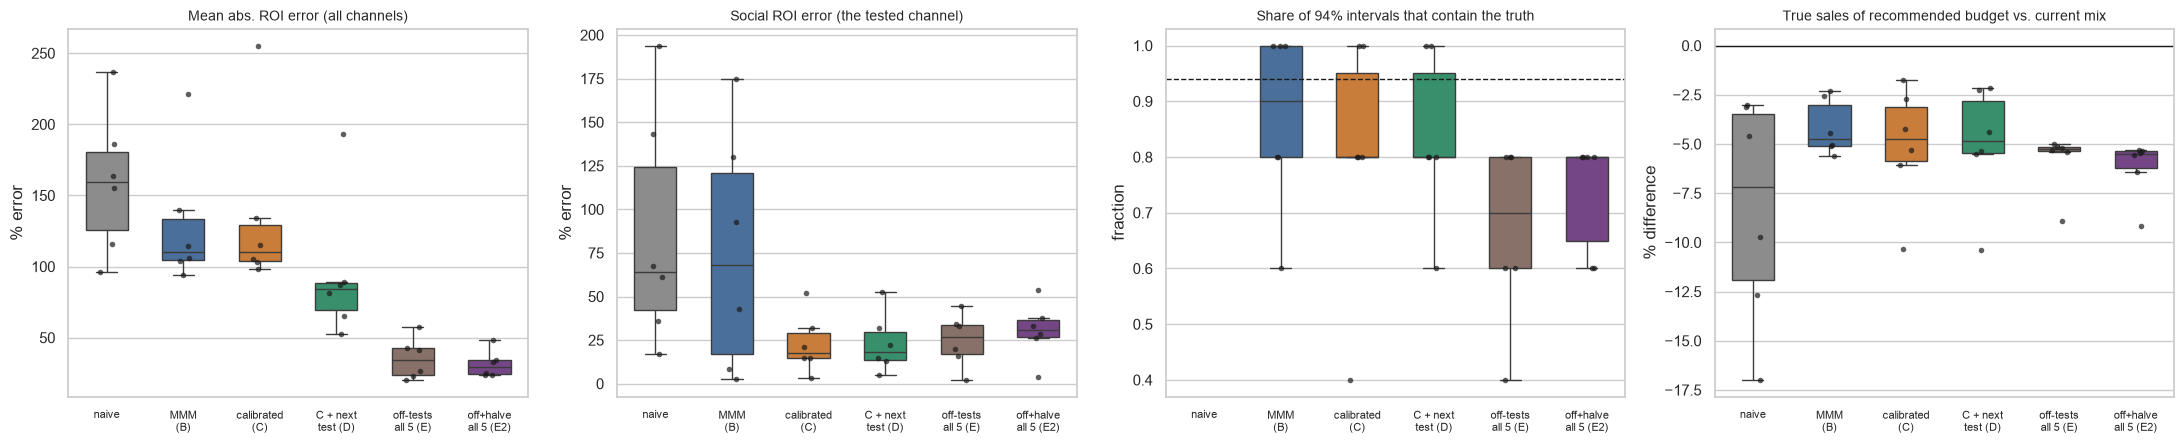

roi_err  social_err  display_err  \
seed model                                                             
1    naive                            186.0       143.0        550.0   
     MMM (B)                          114.0         8.0        292.0   
     calibrated (C)                   115.0        21.0        302.0   
     calibrated+next test (D)          89.0        22.0        314.0   
     off-tests on all 5 (E)            58.0        16.0        159.0   
     off+halve tests on all 5 (E2)     48.0        29.0         95.0   
2    naive                             96.0        17.0         64.0   
     MMM (B)                          106.0        43.0         57.0   
     calibrated (C)                   106.0        15.0         35.0   
     calibrated+next test (D)          53.0        15.0         36.0   
     off-tests on all 5 (E)            23.0         2.0         14.0   
     off+halve tests on all 5 (E2)     25.0        38.0          3.0   
3    naive                            236.0       194.0        684.0   
     MMM (B)                          104.0        93.0         88.0   
     calibrated (C)                    98.0         4.0        127.0   
     calibrated+next test (D)          65.0         5.0        124.0   
     off-tests on all 5 (E)            20.0        33.0         11.0   
     off+halve tests on all 5 (E2)     33.0        54.0         16.0   
4    naive                            116.0        36.0        269.0   
     MMM (B)                           94.0         3.0         34.0   
     calibrated (C)                   103.0        15.0         39.0   
     calibrated+next test (D)          87.0        13.0         37.0   
     off-tests on all 5 (E)            42.0        20.0        122.0   
     off+halve tests on all 5 (E2)     35.0        33.0         49.0   
5    naive                            155.0        61.0        249.0   
     MMM (B)                          139.0       130.0         93.0   
     calibrated (C)                   134.0        32.0        130.0   
     calibrated+next test (D)          81.0        32.0        139.0   
     off-tests on all 5 (E)            43.0        45.0         62.0   
     off+halve tests on all 5 (E2)     24.0         4.0         47.0   
6    naive                            164.0        67.0        237.0   
     MMM (B)                          222.0       175.0         92.0   
     calibrated (C)                   255.0        52.0        358.0   
     calibrated+next test (D)         194.0        52.0        426.0   
     off-tests on all 5 (E)            27.0        34.0          2.0   
     off+halve tests on all 5 (E2)     24.0        26.0          1.0   

                                    coverage  vs_naive  vs_hist next_test  \
seed model                                                                  
1    naive                               NaN       0.0    -12.7     Email   
     MMM (B)                           100.0       8.1     -5.6     Email   
     calibrated (C)                    100.0       9.7     -4.2     Email   
     calibrated+next test (D)          100.0       9.5     -4.4     Email   
     off-tests on all 5 (E)             60.0       4.3     -8.9     Email   
     off+halve tests on all 5 (E2)      60.0       4.0     -9.2     Email   
2    naive                               NaN       0.0     -4.6     Email   
     MMM (B)                           100.0       2.2     -2.5     Email   
     calibrated (C)                    100.0       2.0     -2.7     Email   
     calibrated+next test (D)          100.0       2.4     -2.3     Email   
     off-tests on all 5 (E)             80.0      -0.6     -5.2     Email   
     off+halve tests on all 5 (E2)      80.0      -0.7     -5.3     Email   
3    naive                               NaN       0.0    -17.0     Email   
     MMM (B)                           100.0      14.4     -5.1     Email   
     calibrated (C)                     80.0      13.1     -6.1    

In [17]:
piv = lambda col: fresh.pivot(index="seed", columns="model", values=col)[MODELS]
n = len(ROBUSTNESS_SEEDS)
lt = lambda a, b, col: int((piv(col)[a] < piv(col)[b]).sum())
gt = lambda a, b, col: int((piv(col)[a] > piv(col)[b]).sum())
print(f"Across {n} fresh worlds:")
print(f"  Tested channel (Social): C has lower ROI error than B in {lt('calibrated (C)','MMM (B)','social_err')}/{n} worlds "
      f"(mean {piv('social_err')['MMM (B)'].mean():.0%} -> {piv('social_err')['calibrated (C)'].mean():.0%})")
print(f"  Correlated channel (Display): C has lower error than B in {lt('calibrated (C)','MMM (B)','display_err')}/{n} "
      f"(mean {piv('display_err')['MMM (B)'].mean():.0%} -> {piv('display_err')['calibrated (C)'].mean():.0%})")
print(f"  All channels: C lower mean ROI error than B in {lt('calibrated (C)','MMM (B)','roi_err')}/{n}")
print(f"  Budget: C beats naive in {gt('calibrated (C)','naive','true_sales')}/{n}, beats B in {gt('calibrated (C)','MMM (B)','true_sales')}/{n}")
for m_ in MODELS[1:]:
    print(f"  Budget from '{m_}' beats simply keeping the current mix in {int((piv('vs_hist')[m_] > 0).sum())}/{n} worlds")

fig, ax = plt.subplots(1, 4, figsize=(22, 4.6))
cols = [COL["naive"], COL["B"], COL["C"], COL["D"], "#8d6e63", COL["oracle"]]
short = {m: m.replace("calibrated+next test (D)", "C + next\ntest (D)").replace("off-tests on all 5 (E)", "off-tests\nall 5 (E)").replace("off+halve tests on all 5 (E2)", "off+halve\nall 5 (E2)").replace("calibrated (C)", "calibrated\n(C)").replace("MMM (B)", "MMM\n(B)") for m in MODELS}
for a_, col_, title, ylab in [(ax[0], "roi_err", "Mean abs. ROI error (all channels)", "% error"),
                              (ax[1], "social_err", "Social ROI error (the tested channel)", "% error"),
                              (ax[2], "coverage", "Share of 94% intervals that contain the truth", "fraction"),
                              (ax[3], "vs_hist", "True sales of recommended budget vs. current mix", "% difference")]:
    scale = 1 if col_ == "coverage" else 100
    d_ = fresh.assign(v=fresh[col_] * scale, m=fresh.model.map(short))
    sns.boxplot(data=d_, x="m", y="v", order=[short[m] for m in MODELS], palette=cols, ax=a_, showfliers=False, width=0.55)
    sns.stripplot(data=d_, x="m", y="v", order=[short[m] for m in MODELS], color="k", size=4, ax=a_, alpha=0.7)
    a_.set_title(title, fontsize=10); a_.set_xlabel(""); a_.set_ylabel(ylab); a_.tick_params(axis="x", labelsize=8)
ax[3].axhline(0, color="k", lw=1)
ax[2].axhline(0.94, color="k", ls="--", lw=1)
plt.tight_layout(); plt.savefig(FIG / "06_robustness.png", dpi=150, bbox_inches="tight"); plt.show()

detail = fresh.assign(roi_err=(fresh.roi_err*100).round(0), social_err=(fresh.social_err*100).round(0), display_err=(fresh.display_err*100).round(0),
                      coverage=(fresh.coverage*100).round(0), vs_naive=(fresh.vs_naive*100).round(1), vs_hist=(fresh.vs_hist*100).round(1),
                      test_t=fresh.test_t.round(1)).drop(columns=["true_sales", "gain_captured", "headroom"]).set_index(["seed", "model"])
display(detail)


## 11. One-page recommendation for a marketing VP

*(Written from the calibrated model's output on the main world, with the robustness results folded in. Dollar figures
are model estimates; where the simulation lets us check against the truth, that is shown too, which you could never do with
real data. Everything below is computed, not typed.)*


In [18]:
cur_q = {c: v * 13 for c, v in current_mix_weekly(train).items()}
rec_q = {c: v * 13 for c, v in allocs["calibrated (C)"].items()}
hist_pred = sum(curve_draws(C["params"], c, cur_q[c] / 13) for c in CHANNELS) * 13
rec_pred = sum(curve_draws(C["params"], c, rec_q[c] / 13) for c in CHANNELS) * 13
gain = rec_pred - hist_pred
lo, hi = hdi(gain); p_pos = (gain > 0).mean()
truth_gain = bt.loc["calibrated (C)", "true quarterly incremental sales"] - bt.loc["historical mix", "true quarterly incremental sales"]

moves = pd.DataFrame({"now ($k/qtr)": pd.Series(cur_q) / 1e3, "model-suggested ($k/qtr)": pd.Series(rec_q) / 1e3})
moves["change (%)"] = (moves["model-suggested ($k/qtr)"] / moves["now ($k/qtr)"] - 1) * 100
rt = roi_table(C)
moves["ROI estimate (94% interval)"] = [f"{rt.loc[c,'mean']:.1f} ({rt.loc[c,'lo94']:.1f}-{rt.loc[c,'hi94']:.1f})" for c in moves.index]

beat_hist = int((piv("vs_hist")["calibrated (C)"] > 0).sum())
cov_C = fresh[fresh.model == "calibrated (C)"].coverage.mean()
headroom = fresh.drop_duplicates("seed").headroom.mean()
eB, eC = errs["MMM (B)"], errs["calibrated (C)"]
tested_txt = (f"Social {eB['Social']:.0%} -> {eC['Social']:.0%}, Display {eB['Display']:.0%} -> {eC['Display']:.0%}, "
              f"TV/Search/Email {eB[others].mean():.0%} -> {eC[others].mean():.0%}")
stance = ("**Hold the current mix; do not reallocate on this model's say-so. Fund tests instead.**" if beat_hist < n / 2
          else "**Shift budget as suggested below, but treat the size of the gain as uncertain.**")
mean_E, mean_E2 = fresh[fresh.model.str.startswith("off-tests")].vs_hist.mean(), fresh[fresh.model.str.startswith("off+halve")].vs_hist.mean()

memo = f'''
### Recommendation for next quarter ($1M budget)

{stance}

**Why.** Across {n} independent simulated worlds, the budget recommended by the calibrated MMM beat simply keeping the
current mix in {beat_hist} of {n}. In the main world it predicts a change of **{gain.mean()/1e3:+,.0f}k** in quarterly incremental sales
(94% interval {lo/1e3:+,.0f}k to {hi/1e3:+,.0f}k; {p_pos:.0%} of draws positive), while the *true* change is **{truth_gain/1e3:+,.0f}k**.
Context: knowing the true curves would improve on today's mix by only {headroom:.1%}, so there is little room to add value and
any estimation error can easily cost more than a reallocation earns.

**What the model would do (low confidence):**

{moves.round(0).to_markdown()}

**How much to trust the numbers.**
* ROI *levels* are unreliable: the model attributes {C['marketing_share']:.0%} of all sales to marketing; the truth is {mk.sum()/train.sales.sum():.0%}.
* The stated 94% intervals contain the true ROI only {cov_C:.0%} of the time (calibrated model, fresh worlds). Treat the bands as too narrow.
* Effect of the single Social test on ROI error (uncalibrated -> calibrated): {tested_txt}.
* For reference, the naive-regression approach would have recommended a mix that is {bt.loc['naive','vs historical']:+.1%} versus keeping today's allocation (true sales).

**What to do instead.** Run a geo-lift test on **{NEXT}** next (widest uncertainty in attributed incremental sales among untested channels).
In the simulation we followed that rule: adding the {NEXT} test moved its ROI estimate from {roi_table(C).loc[NEXT,'mean']:.1f} to {roi_table(D).loc[NEXT,'mean']:.1f} (truth {TRUE_ROI[NEXT]:.1f}).
But more tests of the same kind did not fix budgets by themselves: with off-tests on all five channels the budget was {mean_E:+.1%} vs the current mix on average;
adding a halve-spend test to each (two points per curve) gave {mean_E2:+.1%}. A test pins down *average* return; budget decisions need the
*marginal* return, so design tests with at least two spend levels and long enough windows to capture carry-over.

**Ask of finance:** approve a recurring test budget. The model's value comes from experiments that keep it honest, not from the model alone.
'''
display(Markdown(memo))



### Recommendation for next quarter ($1M budget)

**Hold the current mix; do not reallocate on this model's say-so. Fund tests instead.**

**Why.** Across 6 independent simulated worlds, the budget recommended by the calibrated MMM beat simply keeping the
current mix in 0 of 6. In the main world it predicts a change of **+948k** in quarterly incremental sales
(94% interval +521k to +1,341k; 100% of draws positive), while the *true* change is **-41k**.
Context: knowing the true curves would improve on today's mix by only 3.3%, so there is little room to add value and
any estimation error can easily cost more than a reallocation earns.

**What the model would do (low confidence):**

|         |   now ($k/qtr) |   model-suggested ($k/qtr) |   change (%) | ROI estimate (94% interval)   |
|:--------|---------------:|---------------------------:|-------------:|:------------------------------|
| TV      |            384 |                        344 |          -10 | 6.9 (3.0-10.9)                |
| Search  |            192 |                        384 |          100 | 7.9 (5.5-11.6)                |
| Social  |            192 |                         96 |          -50 | 1.5 (0.4-2.6)                 |
| Display |            164 |                         82 |          -50 | 1.0 (0.0-3.9)                 |
| Email   |             68 |                         95 |           38 | 17.0 (1.0-66.8)               |

**How much to trust the numbers.**
* ROI *levels* are unreliable: the model attributes 61% of all sales to marketing; the truth is 23%.
* The stated 94% intervals contain the true ROI only 80% of the time (calibrated model, fresh worlds). Treat the bands as too narrow.
* Effect of the single Social test on ROI error (uncalibrated -> calibrated): Social 30% -> 26%, Display 43% -> 29%, TV/Search/Email 221% -> 221%.
* For reference, the naive-regression approach would have recommended a mix that is -5.2% versus keeping today's allocation (true sales).

**What to do instead.** Run a geo-lift test on **Email** next (widest uncertainty in attributed incremental sales among untested channels).
In the simulation we followed that rule: adding the Email test moved its ROI estimate from 17.0 to 4.0 (truth 6.0).
But more tests of the same kind did not fix budgets by themselves: with off-tests on all five channels the budget was -5.8% vs the current mix on average;
adding a halve-spend test to each (two points per curve) gave -6.2%. A test pins down *average* return; budget decisions need the
*marginal* return, so design tests with at least two spend levels and long enough windows to capture carry-over.

**Ask of finance:** approve a recurring test budget. The model's value comes from experiments that keep it honest, not from the model alone.


## What this does and doesn't show

See the README for the full list of caveats. In short: one simulated data-generating process, a handful of worlds, one MMM
implementation with default sampler settings (some fits show divergences, listed above), and a single geo-test design with 5
treated vs. 5 control regions. It shows how the pieces interact, not a universal verdict on MMM or on calibration.
